# Walk / Run Classification

## 1. Load the Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("walkrun.csv")

## 2. Basic checks

In [2]:
df.head()

,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,2017-6-30,13:51:15:847724020,viktor,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,2017-6-30,13:51:16:246945023,viktor,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,2017-6-30,13:51:16:446233987,viktor,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,2017-6-30,13:51:16:646117985,viktor,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,2017-6-30,13:51:16:846738994,viktor,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


In [3]:
df.tail()

,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
88583,2017-7-9,20:9:15:317911028,viktor,0,0,0.3084,-0.8376,-0.1327,0.4823,2.0124,0.6048
88584,2017-7-9,20:9:15:517889022,viktor,0,0,0.4977,-1.0027,-0.4397,0.1022,-1.2565,-0.0761
88585,2017-7-9,20:9:15:717828989,viktor,0,0,0.4587,-1.1780,-0.2827,-1.4500,-0.2792,-1.2616
88586,2017-7-9,20:9:15:917932987,viktor,0,0,0.2590,-0.8582,-0.0759,-1.5165,0.4560,-1.7755
88587,2017-7-9,20:9:16:117410004,viktor,0,0,0.3140,-0.8008,-0.0911,0.1183,1.0850,1.2814


In [4]:
df.shape

(88588, 11)

In [5]:
df.dtypes

date               object
time               object
username           object
wrist               int64
activity            int64
acceleration_x    float64
acceleration_y    float64
acceleration_z    float64
gyro_x            float64
gyro_y            float64
gyro_z            float64
dtype: object

In [6]:
df.isnull().sum()

date              0
time              0
username          0
wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64

In [7]:
df.nunique()

date                 12
time              88588
username              1
wrist                 2
activity              2
acceleration_x    30307
acceleration_y    23957
acceleration_z    19698
gyro_x            40988
gyro_y            38957
gyro_z            51296
dtype: int64

In [8]:
sensor_cols = [
    "acceleration_x", "acceleration_y", "acceleration_z",
    "gyro_x", "gyro_y", "gyro_z"
]
required_cols = sensor_cols + ["activity", "date"]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

## 3.Exploratory Data Analysis (EDA)

### 3.1 Univariate analysis

,count,mean,std,min,25%,50%,75%,max
acceleration_x,88588.0,-0.074811,1.009299,-5.3505,-0.381800,-0.0595,0.355500,5.6033
acceleration_y,88588.0,-0.562585,0.658458,-3.2990,-1.033500,-0.7591,-0.241775,2.6680
acceleration_z,88588.0,-0.313956,0.486815,-3.7538,-0.376000,-0.2210,-0.085900,1.6403
gyro_x,88588.0,0.004160,1.253423,-4.4306,-0.920700,0.0187,0.888800,4.8742
gyro_y,88588.0,0.037203,1.198725,-7.4647,-0.644825,0.0393,0.733700,8.4980
gyro_z,88588.0,0.022327,1.914423,-9.4800,-1.345125,0.0069,1.398200,11.2662


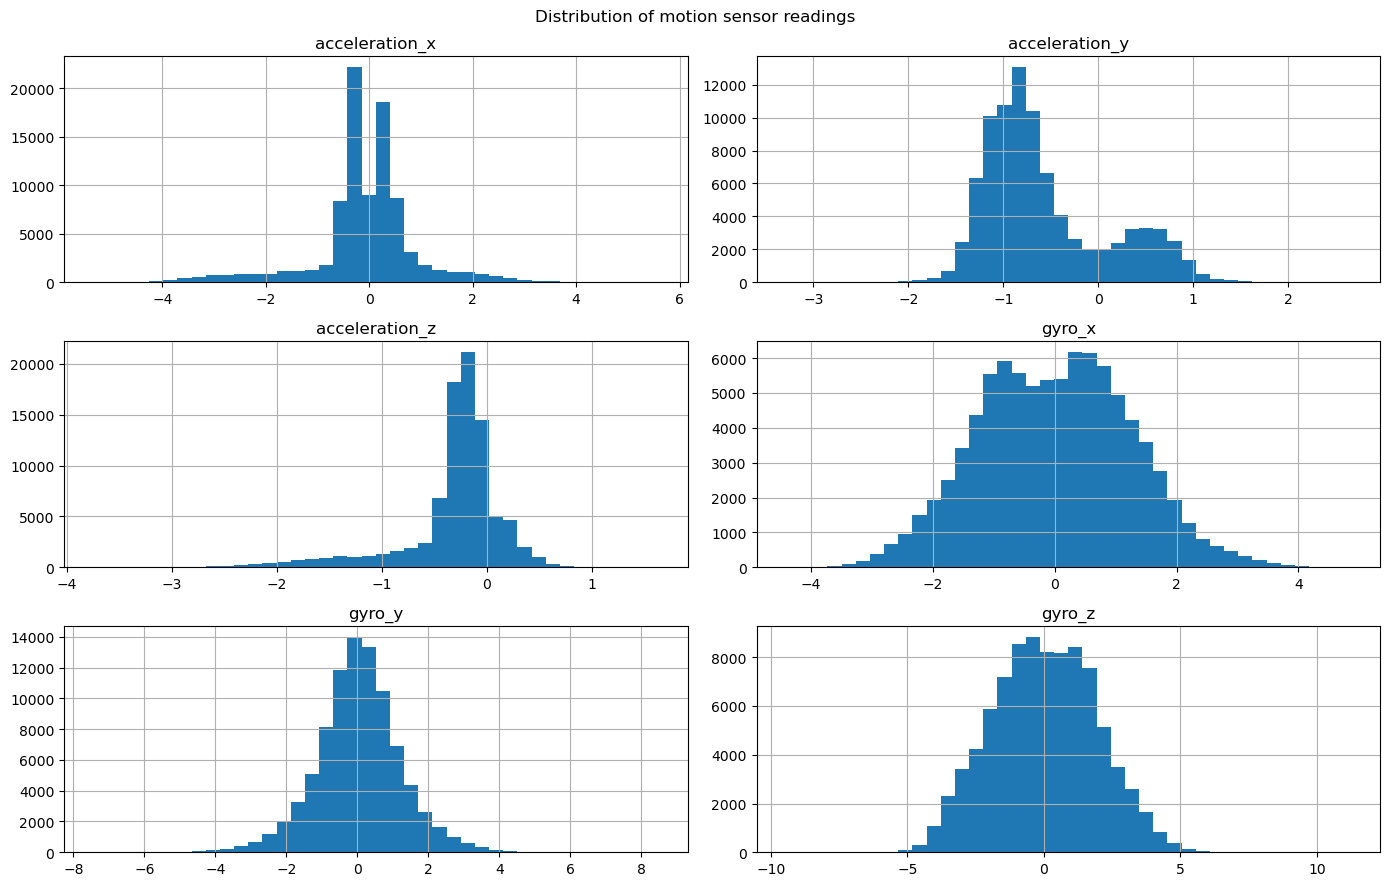

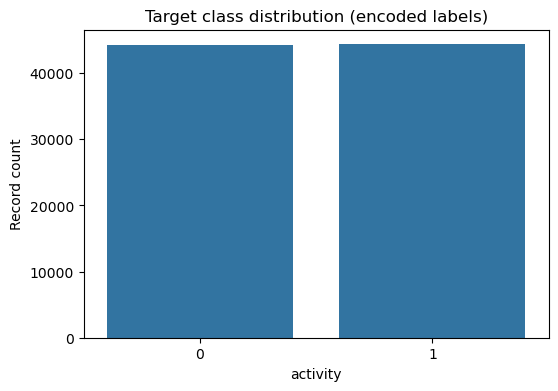

In [9]:
display(df[sensor_cols].describe().T)
df[sensor_cols].hist(figsize=(14, 9), bins=40)
plt.suptitle("Distribution of motion sensor readings")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="activity")
plt.title("Target class distribution (encoded labels)")
plt.xlabel("activity")
plt.ylabel("Record count")
plt.show()

### 3.2 Bivariate analysis

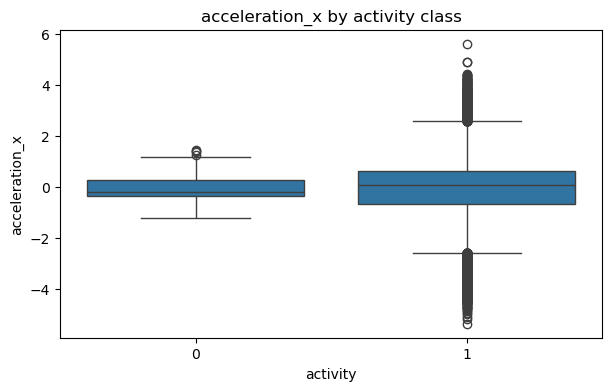

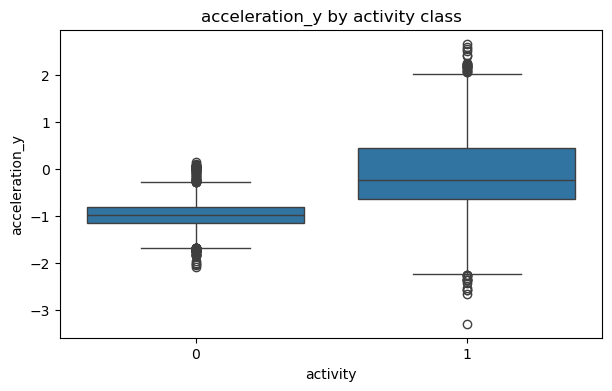

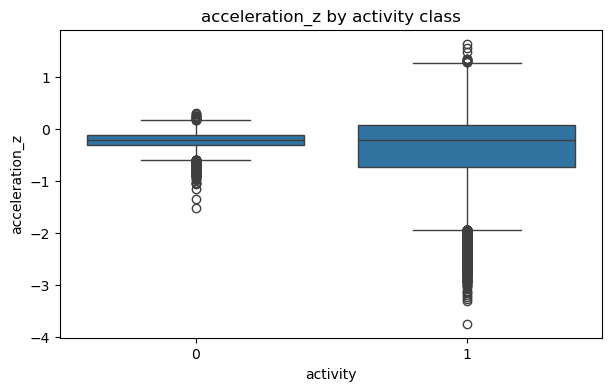

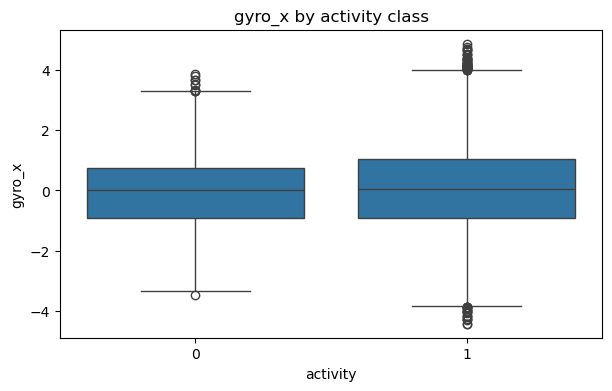

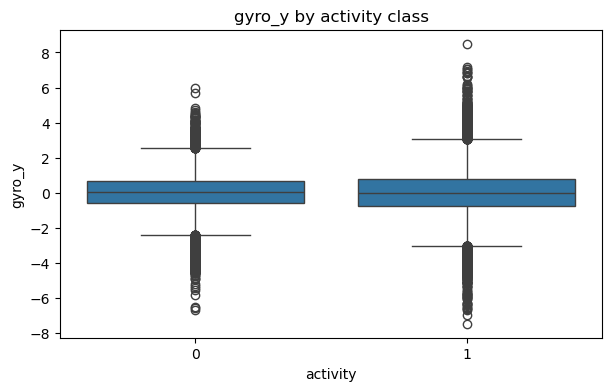

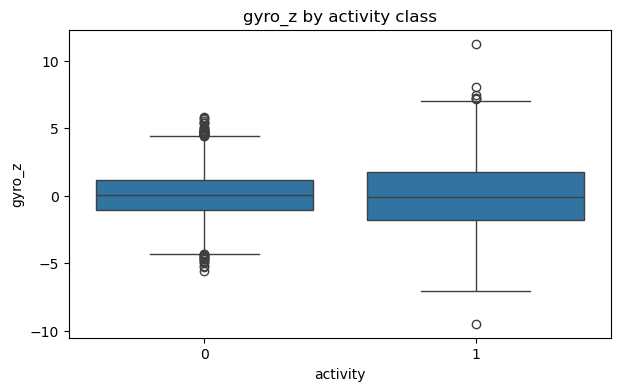

activity,0,1
acceleration_x,-0.056871,-0.092695
acceleration_y,-0.984355,-0.142165
acceleration_z,-0.220126,-0.407486
gyro_x,-0.047131,0.055288
gyro_y,0.022730,0.051630
gyro_z,0.037871,0.006834


In [10]:
for col in sensor_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="activity", y=col)
    plt.title(f"{col} by activity class")
    plt.show()

display(df.groupby("activity")[sensor_cols].mean().T)

### 3.3 Multivariate analysis

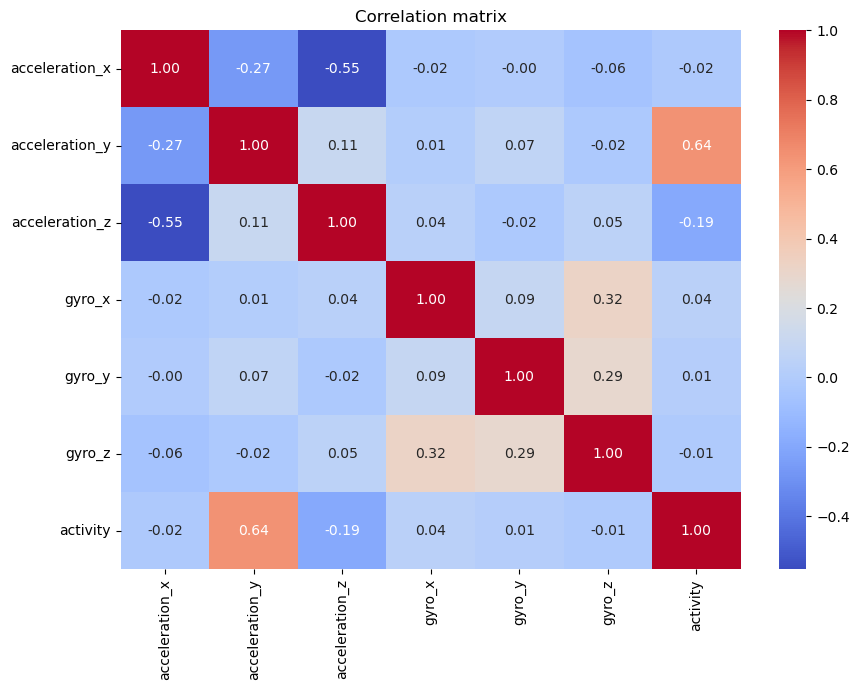

activity,0,1
date,,
2017-6-30,0.310872,0.689128
2017-7-1,0.706022,0.293978
2017-7-10,1.000000,0.000000
2017-7-11,0.000000,1.000000
2017-7-15,0.098815,0.901185
2017-7-16,1.000000,0.000000
2017-7-17,0.400704,0.599296
2017-7-2,0.109077,0.890923
2017-7-4,0.100465,0.899535


In [11]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[sensor_cols + ["activity"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()


date_activity = pd.crosstab(df["date"], df["activity"], normalize="index")
display(date_activity)

## 4. Feature engineering and feature selection

In [12]:
df["acceleration_magnitude"] = np.sqrt(
    df["acceleration_x"]**2 + df["acceleration_y"]**2 + df["acceleration_z"]**2
)
df["gyro_magnitude"] = np.sqrt(
    df["gyro_x"]**2 + df["gyro_y"]**2 + df["gyro_z"]**2
)

feature_cols = sensor_cols + ["acceleration_magnitude", "gyro_magnitude"]
if "wrist" in df.columns and df["wrist"].notna().any():
    feature_cols.append("wrist")

X = df[feature_cols].copy()
y = df["activity"].copy()
groups = df["date"].astype(str)  

print("Features:", feature_cols)
display(X.head())

Features: ['acceleration_x', 'acceleration_y', 'acceleration_z', 'gyro_x', 'gyro_y', 'gyro_z', 'acceleration_magnitude', 'gyro_magnitude', 'wrist']


,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z,acceleration_magnitude,gyro_magnitude,wrist
0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296,0.825148,2.930374,0
1,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269,1.329887,0.217731,0
2,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367,1.547307,2.603424,0
3,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336,0.871729,2.964524,0
4,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922,1.048889,2.530928,0


## 5. Train/test split

In [13]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
import joblib
import os
RANDOM_STATE = 42

In [14]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train dates:", groups.iloc[train_idx].nunique(), "Test dates:", groups.iloc[test_idx].nunique())
print("Train class proportions:")
display(y_train.value_counts(normalize=True).sort_index())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index())

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("The selected date split does not contain both classes in train and test. Change RANDOM_STATE or test_size and rerun.")

Train shape: (69959, 9) Test shape: (18629, 9)
Train dates: 9 Test dates: 3
Train class proportions:


activity
0    0.496805
1    0.503195
Name: proportion, dtype: float64

Test class proportions:


activity
0    0.508186
1    0.491814
Name: proportion, dtype: float64

## 6. Model selection and model creation

In [15]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=250, max_depth=None, min_samples_leaf=2,
                                         class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(n_estimators=250, min_samples_leaf=2,
                                       class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=RANDOM_STATE))
    ]),
    "MLP Neural Network": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=250,
                                early_stopping=True, random_state=RANDOM_STATE))
    ])
}


results = []
fitted_models = {}

for name, estimator in models.items():
    print("Training:", name)
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_weighted": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0)
    })
    fitted_models[name] = estimator

comparison = pd.DataFrame(results).sort_values("F1_weighted", ascending=False).reset_index(drop=True)
display(comparison)

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting
Training: MLP Neural Network


,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted
0,MLP Neural Network,0.986419,0.986498,0.986419,0.986417
1,Hist Gradient Boosting,0.986204,0.986214,0.986204,0.986204
2,Extra Trees,0.985829,0.985831,0.985829,0.985828
3,Random Forest,0.985238,0.985244,0.985238,0.985238
4,Decision Tree,0.974932,0.975209,0.974932,0.974923
5,Logistic Regression,0.940523,0.940938,0.940523,0.940492


### 6.1 Compare model performance

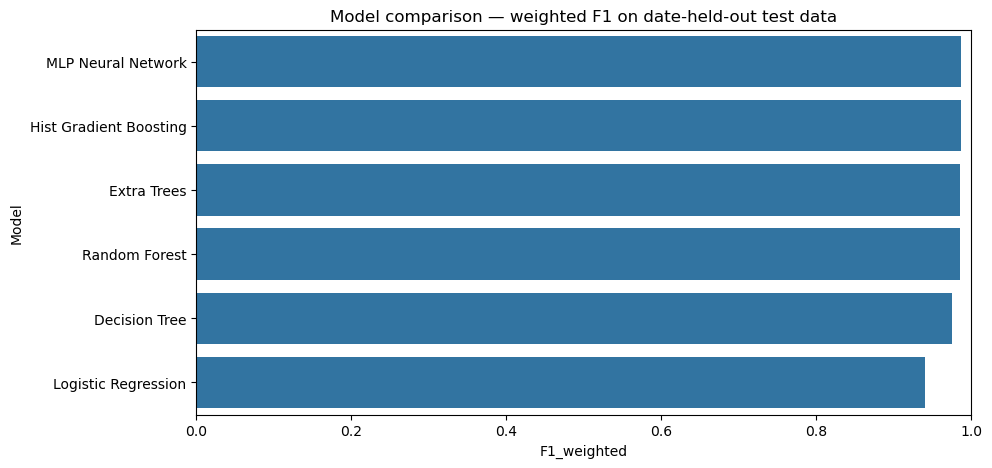

Best initial model by weighted F1: MLP Neural Network


In [16]:
plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x="F1_weighted", y="Model")
plt.xlim(0, 1)
plt.title("Model comparison — weighted F1 on date-held-out test data")
plt.show()

best_initial_name = comparison.loc[0, "Model"]
print("Best initial model by weighted F1:", best_initial_name)

## 7. Hyperparameter tuning

In [17]:
n_splits = min(5, groups_train.nunique())
if n_splits < 2:
    raise ValueError("Not enough distinct training dates for grouped cross-validation.")

cv = GroupKFold(n_splits=n_splits)
rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
])

param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 15],
    "model__min_samples_leaf": [1, 2]
}

grid = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", grid.best_params_)
print("Best grouped CV weighted F1:", grid.best_score_)
tuned_model = grid.best_estimator_

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 250}
Best grouped CV weighted F1: 0.979126457847839


## 8. Final model evaluation

Final test accuracy: 0.9846475924633635
Final test weighted precision: 0.9846512177211953
Final test weighted recall: 0.9846475924633635
Final test weighted F1: 0.984647179854587
\nClassification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      9467
           1       0.99      0.98      0.98      9162

    accuracy                           0.98     18629
   macro avg       0.98      0.98      0.98     18629
weighted avg       0.98      0.98      0.98     18629



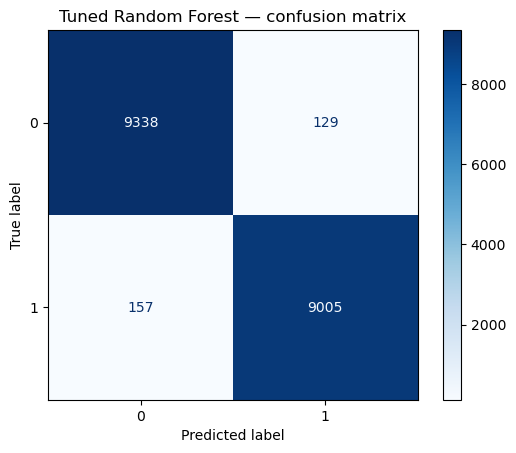

ROC-AUC: 0.9984278215297538


In [18]:
final_pred = tuned_model.predict(X_test)

print("Final test accuracy:", accuracy_score(y_test, final_pred))
print("Final test weighted precision:", precision_score(y_test, final_pred, average="weighted", zero_division=0))
print("Final test weighted recall:", recall_score(y_test, final_pred, average="weighted", zero_division=0))
print("Final test weighted F1:", f1_score(y_test, final_pred, average="weighted", zero_division=0))
print("\\nClassification report:")
print(classification_report(y_test, final_pred, zero_division=0))

cm = confusion_matrix(y_test, final_pred, labels=sorted(y.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
disp.plot(cmap="Blues")
plt.title("Tuned Random Forest — confusion matrix")
plt.show()

if hasattr(tuned_model, "predict_proba"):
    proba = tuned_model.predict_proba(X_test)
    if proba.shape[1] == 2:
        print("ROC-AUC:", roc_auc_score(y_test, proba[:, 1]))

## 9. Save the trained model as a PKL file

In [19]:
MODEL_PATH = "walkrun_classifier.pkl"
joblib.dump({
    "model": tuned_model,
    "feature_columns": feature_cols,
    "target_classes": sorted(y.unique())
}, MODEL_PATH)

print("Saved:", os.path.abspath(MODEL_PATH))

Saved: C:\Users\hetpa\PROJECT 2\walkrun_classifier.pkl


## 10. Test the saved model with a sample sensor record

In [20]:
artifact = joblib.load(MODEL_PATH)
loaded_model = artifact["model"]
saved_features = artifact["feature_columns"]

sample_record = X_test.iloc[[0]].copy()
actual_class = int(y_test.iloc[0])
predicted_class = int(loaded_model.predict(sample_record[saved_features])[0])

print("Sample input:")
display(sample_record)
print("Actual encoded activity:", actual_class)
print("Predicted encoded activity:", predicted_class)
print("Prediction:", "Correct" if actual_class == predicted_class else "Incorrect")

Sample input:


,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z,acceleration_magnitude,gyro_magnitude,wrist
0,0.265,-0.7814,-0.0076,-0.059,0.0325,-2.9296,0.825148,2.930374,0


Actual encoded activity: 0
Predicted encoded activity: 0
Prediction: Correct


### 10.1 Predict using a manually entered new record

In [21]:
new_sensor_reading = {
    "acceleration_x": 0.12,
    "acceleration_y": -0.95,
    "acceleration_z": 0.20,
    "gyro_x": 0.03,
    "gyro_y": -0.02,
    "gyro_z": 0.15,
    "acceleration_magnitude": np.sqrt(0.12**2 + (-0.95)**2 + 0.20**2),
    "gyro_magnitude": np.sqrt(0.03**2 + (-0.02)**2 + 0.15**2)
}
if "wrist" in saved_features:
    new_sensor_reading["wrist"] = 1  

new_record_df = pd.DataFrame([new_sensor_reading])[saved_features]
new_prediction = loaded_model.predict(new_record_df)[0]
print("Predicted encoded activity:", int(new_prediction))
if hasattr(loaded_model, "predict_proba"):
    print("Class probabilities:", dict(zip(loaded_model.classes_, loaded_model.predict_proba(new_record_df)[0])))

Predicted encoded activity: 1
Class probabilities: {np.int64(0): np.float64(0.252), np.int64(1): np.float64(0.748)}


## 11. Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Continuous sensor readings may be correlated across nearby rows | Split by `date` groups | Reduces leakage from the same recording day appearing in both train and test |
| `date`, `time`, and `username` are metadata | Excluded from predictors | Avoids learning recording/session identifiers instead of movement |
| Raw x/y/z values may be harder to interpret jointly | Acceleration and gyroscope magnitude features | Summarizes total movement across the three axes |
| Models have different scale sensitivity | StandardScaler in Logistic Regression and MLP pipelines | Scaling supports distance/gradient-based models |
| Models can overfit | Compare several algorithms and tune with GroupKFold | Measures generalization across date groups |
| Class names are not defined in the brief | Preserve encoded labels 0 and 1 | Avoids guessing which integer means walking or running |

## 12. Final conclusion

This notebook completes the requested analysis and classification workflow: domain understanding, basic checks, univariate/bivariate/multivariate EDA, feature engineering, model selection, model fitting, model comparison, hyperparameter tuning, final evaluation, model saving, and sample prediction.
